In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

excel_path = Path('/Users/piraira/Desktop/finalResultados_RM_EEG_BASE_ACTUALIZADA_48_PACIENTES.xlsx')
sheet_name = 'Base_anonimizada'

df = pd.read_excel(excel_path, sheet_name=sheet_name)
df.columns = [str(col).strip() for col in df.columns]
mask_valid = ~(
    df['Resultado EEG'].fillna('').astype(str).str.contains('Sin informe', case=False, na=False)
    | df['Resultado RM'].fillna('').astype(str).str.contains('Sin informe', case=False, na=False)
)
df_valid = df.loc[mask_valid].copy()
df_valid['Edad (años)'] = pd.to_numeric(df_valid['Edad (años)'], errors='coerce')

print(f"Archivo: {excel_path}")
print(f"Hoja: {sheet_name}")
print(f"Registros: {len(df)}")
print(f"Registros válidos: {len(df_valid)}")

display(df)

Archivo: /Users/piraira/Desktop/finalResultados_RM_EEG_BASE_ACTUALIZADA_48_PACIENTES.xlsx
Hoja: Base_anonimizada
Registros: 48
Registros válidos: 48


,Código,Edad original,Edad (años),Sexo,Fecha EEG,Resultado EEG,Tipo de hallazgo EEG,Localización EEG,Lateralidad EEG,Fecha RM,Resultado RM,Hallazgo RM,Localización RM,Lateralidad RM,Concordancia global,Origen
0,P001,11a 10m 14d,11.8717,M,2026-05-02,Alterado,Actividad epileptiforme interictal,Parietal / temporo-parietal,Bilateral independiente,2026-08-13,Normal,Sin lesión relevante,No aplica,No aplica/No especificada,Discordante,Anterior (33)
1,P002,4a 5m 28d,4.4933,M,2026-05-14,Normal,Normal,No aplica,No aplica/No especificada,2026-08-14,Normal,Sin lesión relevante,No aplica,No aplica/No especificada,Concordante normal,Anterior (33)
2,P003,5a 11m 19d,5.9687,F,2026-07-11,Normal,Normal,No aplica,No aplica/No especificada,2026-08-08,Normal,Sin lesión relevante,No aplica,No aplica/No especificada,Concordante normal,Anterior (33)
3,P004,8a 10m 12d,8.8662,F,2026-03-23,Normal,Normal,No aplica,No aplica/No especificada,2026-08-03,Normal,Sin lesión relevante,No aplica,No aplica/No especificada,Concordante normal,Anterior (33)
4,P005,1a 4m 16d,1.3771,M,2026-07-06,Normal,Normal,No aplica,No aplica/No especificada,2026-08-04,Normal,Sin lesión relevante,No aplica,No aplica/No especificada,Concordante normal,Anterior (33)
5,P006,7a 9m 14d,7.7883,F,2026-05-15,Alterado,Actividad epileptiforme interictal,Centro-parietal,Izquierda,2026-08-05,Normal,Sin lesión relevante,No aplica,No aplica/No especificada,Discordante,Anterior (33)
6,P007,11m 13d,0.9523,F,2026-07-28,Normal,Normal,No aplica,No aplica/No especificada,2023-08-01,Alterado,"Hidrocefalia tetraventricular, aparentemente c...",Ventricular / occipital,No aplica/No especificada,Discordante,Anterior (33)
7,P008,3a 10m 28d,3.9100,M,2026-07-03,Alterado,Actividad epileptiforme interictal,Posterior,Derecha,2026-08-01,Normal,Sin lesión relevante,No aplica,No aplica/No especificada,Discordante,Anterior (33)
8,P009,8a 2m 11d,8.1968,F,2026-06-04,Normal,Normal,No aplica,No aplica/No especificada,2026-07-31,Normal,Sin lesión relevante,No aplica,No aplica/No especificada,Concordante normal,Anterior (33)
9,P010,8a 1m,8.0833,M,2026-03-07,Normal,Normal,No aplica,No aplica/No especificada,2026-07-31,Normal,Sin lesión relevante,No aplica,No aplica/No especificada,Concordante normal,Anterior (33)


## Procesamiento y resultados de la cohorte

### Objetivos del análisis

**Objetivo general:** Describir los hallazgos de resonancia magnética cerebral con protocolo de epilepsia y electroencefalograma, y evaluar su concordancia en los 48 pacientes pediátricos incluidos.

**Objetivos específicos:**
1. Caracterizar a los pacientes según edad y sexo, considerando la disponibilidad de los datos.
2. Describir los resultados y hallazgos de EEG y RM, incluidas las localizaciones consignadas cuando estén disponibles.
3. Cuantificar la concordancia global entre la clasificación normal/alterado del EEG y de la RM mediante una tabla 2×2, porcentaje de acuerdo y Kappa de Cohen.

La agrupación de pacientes en cuatro patrones se utiliza únicamente como resumen descriptivo de la tabla de concordancia; no se aplica clustering ni se interpreta como una clasificación clínica validada.

In [2]:
edad_summary = df_valid['Edad (años)'].describe().to_frame(name='Edad (años)')
display(edad_summary)

,Edad (años)
count,47.000000
mean,6.518472
std,3.132402
min,0.769200
25%,4.446150
50%,6.915500
75%,8.433100
max,12.965900


**Objetivo específico 1. Caracterizar a los pacientes según edad y sexo.** La distribución etaria y sus resúmenes por resultado se describen con los datos disponibles; un participante no tiene edad registrada.

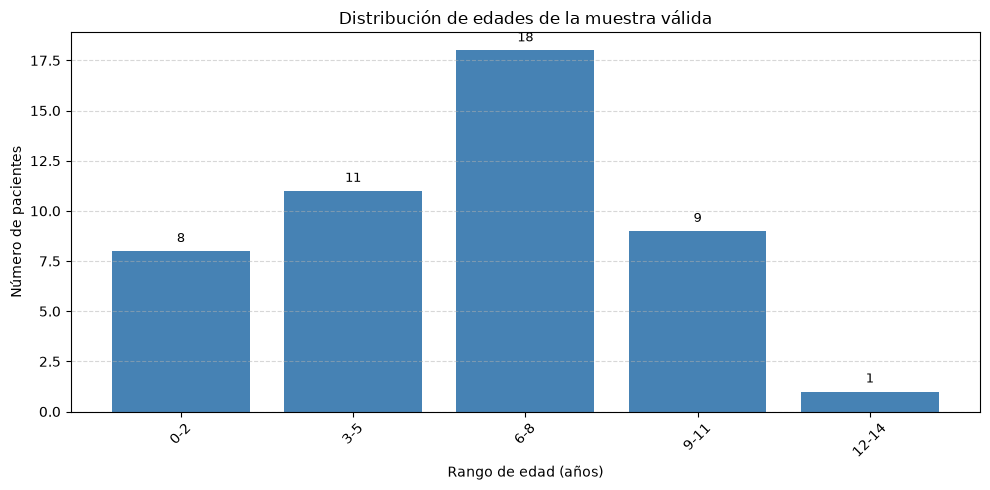

Conteo por rango de edad (3 años):
Edad_rango_3a
0-2       8
3-5      11
6-8      18
9-11      9
12-14     1
Name: count, dtype: int64


In [3]:
# Distribución de edades de la muestra válida (rangos de 3 años)

# Preparación
mask_valid = ~(
    df['Resultado EEG'].fillna('').astype(str).str.contains('Sin informe', case=False, na=False)
    | df['Resultado RM'].fillna('').astype(str).str.contains('Sin informe', case=False, na=False)
)
df_valid = df.loc[mask_valid].copy()

df_valid['Edad (años)'] = pd.to_numeric(df_valid['Edad (años)'], errors='coerce')
max_edad = int(df_valid['Edad (años)'].max())
bins = list(range(0, max_edad + 4, 3))
labels = [f'{i}-{i+2}' for i in range(0, max_edad + 1, 3)]

df_valid['Edad_rango_3a'] = pd.cut(
    df_valid['Edad (años)'],
    bins=bins,
    right=False,
    include_lowest=True,
    labels=labels
)

edades_counts = df_valid['Edad_rango_3a'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
bar_container = plt.bar(edades_counts.index.astype(str), edades_counts.values, color='steelblue')
plt.title('Distribución de edades de la muestra válida')
plt.xlabel('Rango de edad (años)')
plt.ylabel('Número de pacientes')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar, value in zip(bar_container, edades_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.3,
        str(value),
        ha='center',
        va='bottom',
        fontsize=9,
        color='black'
    )

plt.tight_layout()
plt.show()

print('Conteo por rango de edad (3 años):')
print(edades_counts)


Se incluyeron los 48 pacientes con resultados clasificables de EEG y RM. No se excluyeron casos por falta de edad: el análisis de edad utiliza los 47 registros disponibles, mientras que los análisis de resultados y concordancia utilizan los 48.

## Objetivo específico 2. Descripción de resultados de EEG y RM

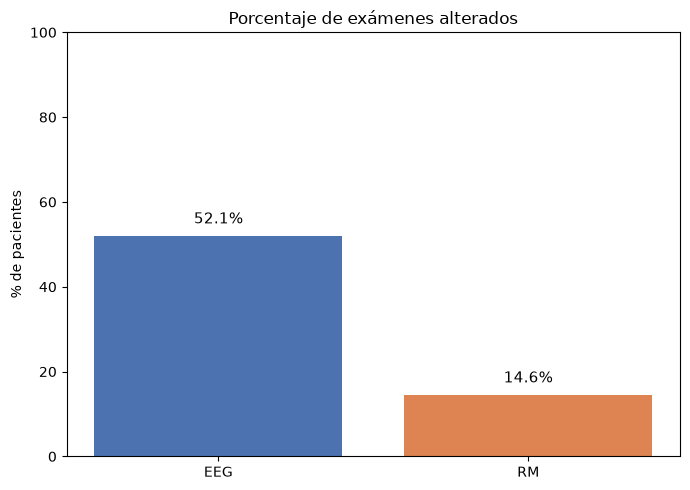

Pacientes excluidos por 'Sin informe': 0
Pacientes válidos para cálculo: 48
EEG alterado: 52.1%
RM alterado: 14.6%


In [4]:
# Gráfico de porcentaje de exámenes alterados
import matplotlib.pyplot as plt

# Excluir filas con 'Sin informe' en cualquiera de los dos exámenes
mask_valid = ~(
    df['Resultado EEG'].fillna('').astype(str).str.contains('Sin informe', case=False, na=False)
    | df['Resultado RM'].fillna('').astype(str).str.contains('Sin informe', case=False, na=False)
)

df_valid = df.loc[mask_valid].copy()

eeg_values = df_valid['Resultado EEG'].fillna('').astype(str).str.lower()
rm_values = df_valid['Resultado RM'].fillna('').astype(str).str.lower()

patron_alterado = 'alterado|no clasificable|anormal|patologico|patológico'

eeg_pct = eeg_values.str.contains(patron_alterado, case=False, na=False).mean() * 100
rm_pct = rm_values.str.contains(patron_alterado, case=False, na=False).mean() * 100

labels = ['EEG', 'RM']
values = [eeg_pct, rm_pct]

plt.figure(figsize=(7, 5))
plt.bar(labels, values, color=['#4C72B0', '#DD8452'])
plt.title('Porcentaje de exámenes alterados')
plt.ylabel('% de pacientes')
plt.ylim(0, 100)

[plt.text(i, v + 2, f'{v:.1f}%', ha='center', va='bottom', fontsize=11) for i, v in enumerate(values)]

plt.tight_layout()
plt.show()

print(f"Pacientes excluidos por 'Sin informe': {(~mask_valid).sum()}")
print(f"Pacientes válidos para cálculo: {len(df_valid)}")
print(f"EEG alterado: {eeg_pct:.1f}%")
print(f"RM alterado: {rm_pct:.1f}%")

En la cohorte de 48 pacientes, el EEG presentó 25 resultados alterados (52,1%) y la RM 7 (14,6%). Estas frecuencias son descriptivas y no comparan sensibilidad diagnóstica.

In [5]:
# Estadísticas de edad (Media, Mediana, Q1, Q3, RIC, Desviación Estándar) por grupo y examen

mask_valid = ~(
    df['Resultado EEG'].fillna('').astype(str).str.contains('Sin informe', case=False, na=False)
    | df['Resultado RM'].fillna('').astype(str).str.contains('Sin informe', case=False, na=False)
)
df_valid = df.loc[mask_valid].copy()
df_valid['Edad (años)'] = pd.to_numeric(df_valid['Edad (años)'], errors='coerce')

def estado_examen(valor):
    valor = str(valor).lower()
    if 'alterado' in valor or 'no clasificable' in valor or 'anormal' in valor or 'patologico' in valor or 'patológico' in valor:
        return 'Alterado'
    elif 'normal' in valor:
        return 'Normal'
    return 'No clasificado'

for examen, col in [('EEG', 'Resultado EEG'), ('RM', 'Resultado RM')]:
    df_examen = df_valid.copy()
    df_examen['estado'] = df_examen[col].apply(estado_examen)
    
    print(f"=== {examen}: Resumen Estadístico de Edad por Grupo ===")
    resumen_grupo = df_examen.groupby('estado')['Edad (años)'].agg(
        N='count',
        Media='mean',
        Mediana='median',
        Q1=lambda x: x.quantile(0.25),
        Q3=lambda x: x.quantile(0.75),
        RIC=lambda x: x.quantile(0.75) - x.quantile(0.25),
        Desv_Estandar='std'
    ).round(2)
    display(resumen_grupo)


=== EEG: Resumen Estadístico de Edad por Grupo ===


,N,Media,Mediana,Q1,Q3,RIC,Desv_Estandar
estado,,,,,,,
Alterado,25,6.78,7.24,5.15,8.67,3.52,2.91
Normal,22,6.22,6.88,3.41,8.19,4.78,3.41


=== RM: Resumen Estadístico de Edad por Grupo ===


,N,Media,Mediana,Q1,Q3,RIC,Desv_Estandar
estado,,,,,,,
Alterado,7,3.93,3.21,1.64,6.24,4.6,2.82
Normal,40,6.97,7.15,5.02,8.92,3.9,2.99


* **EEG:** La mediana de edad fue 7,24 años entre los resultados alterados (n=25 con edad disponible) y 6,88 años entre los normales (n=22 con edad disponible). La diferencia es descriptiva.
* **RM:** La mediana fue 3,21 años en los resultados alterados (n=7) y 7,15 años en los normales (n=40 con edad disponible). Interpretar con cautela por el número reducido de RM alteradas y un dato de edad faltante.

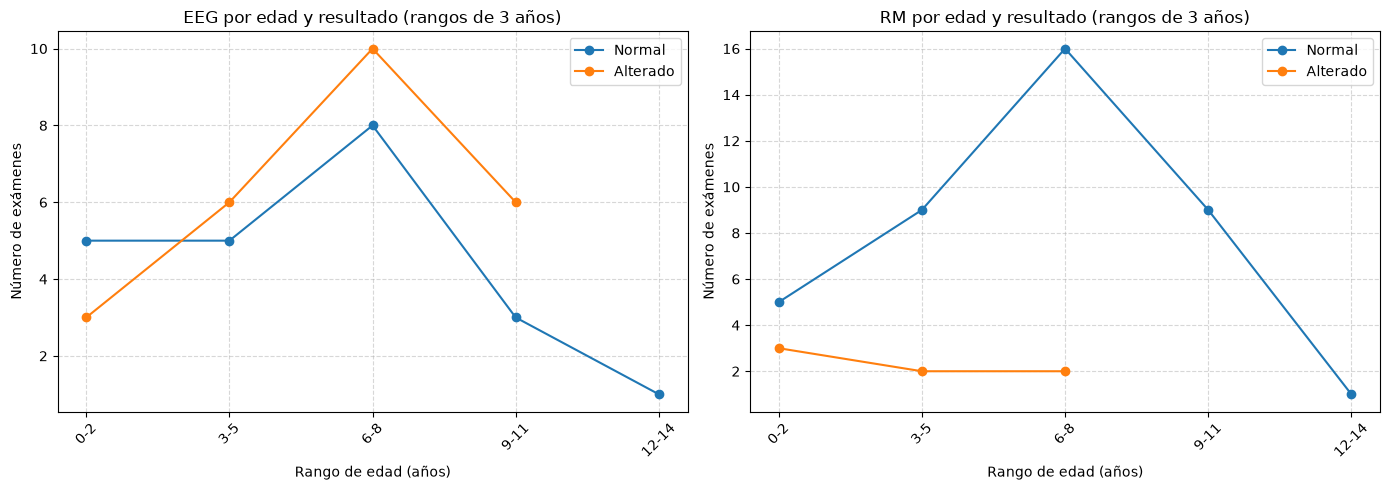

In [6]:
# Gráfico de distribución de edades por resultado (Normal vs Alterado) para EEG y RM

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Excluir filas con 'Sin informe'
mask_valid = ~(
    df['Resultado EEG'].fillna('').astype(str).str.contains('Sin informe', case=False, na=False)
    | df['Resultado RM'].fillna('').astype(str).str.contains('Sin informe', case=False, na=False)
)
df_valid = df.loc[mask_valid].copy()

df_valid['Edad (años)'] = pd.to_numeric(df_valid['Edad (años)'], errors='coerce')
max_edad = int(df_valid['Edad (años)'].max())
bins = list(range(0, max_edad + 4, 3))
labels = [f'{i}-{i+2}' for i in range(0, max_edad + 1, 3)]

df_valid['Rango_edad'] = pd.cut(
    df_valid['Edad (años)'],
    bins=bins,
    right=False,
    include_lowest=True,
    labels=labels
)

def clasificar(val):
    val = str(val).lower()
    if any(k in val for k in ['alterado', 'no clasificable', 'anormal', 'patologico', 'patológico']):
        return 'Alterado'
    elif 'normal' in val:
        return 'Normal'
    return 'Otro'

df_valid['Estado_EEG'] = df_valid['Resultado EEG'].apply(clasificar)
df_valid['Estado_RM'] = df_valid['Resultado RM'].apply(clasificar)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, (examen, col_estado) in enumerate([('EEG', 'Estado_EEG'), ('RM', 'Estado_RM')]):
    pivot = pd.crosstab(df_valid['Rango_edad'], df_valid[col_estado])
    pivot_plot = pivot.replace(0, np.nan)
    ax = axes[i]
    for cat in ['Normal', 'Alterado']:
        if cat in pivot_plot.columns:
            ax.plot(pivot_plot.index.astype(str), pivot_plot[cat], marker='o', label=cat)
    ax.set_title(f'{examen} por edad y resultado (rangos de 3 años)')
    ax.set_xlabel('Rango de edad (años)')
    ax.set_ylabel('Número de exámenes')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend()
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


Por rangos de tres años, hubo RM alteradas en los grupos de 0–2, 3–5 y 6–8 años, pero no en 9–14 años. Los EEG alterados aparecieron en todos los rangos. Estas frecuencias describen la cohorte; no permiten inferir una asociación por edad.

### Localización y lateralidad de los exámenes alterados

In [7]:
# Frecuencia de localización en exámenes alterados para EEG y RM

mask_valid = ~(
    df['Resultado EEG'].fillna('').astype(str).str.contains('Sin informe', case=False, na=False)
    | df['Resultado RM'].fillna('').astype(str).str.contains('Sin informe', case=False, na=False)
)
df_valid = df.loc[mask_valid].copy()

def estado_examen(valor):
    valor = str(valor).lower()
    if any(k in valor for k in ['alterado', 'no clasificable', 'anormal', 'patologico', 'patológico']):
        return 'Alterado'
    elif 'normal' in valor:
        return 'Normal'
    return 'No clasificado'

df_valid['Estado_EEG'] = df_valid['Resultado EEG'].apply(estado_examen)
df_valid['Estado_RM'] = df_valid['Resultado RM'].apply(estado_examen)

# EEG
print(f"=== EEG: Distribución de Localizaciones en Casos Alterados (N = {(df_valid['Estado_EEG'] == 'Alterado').sum()}) ===")
loc_eeg = df_valid[df_valid['Estado_EEG'] == 'Alterado']['Localización EEG'].value_counts().to_frame(name='Número de Exámenes')
display(loc_eeg)

print("\n" + "="*60 + "\n")

# RM
print(f"=== RM: Distribución de Localizaciones en Casos Alterados (N = {(df_valid['Estado_RM'] == 'Alterado').sum()}) ===")
loc_rm = df_valid[df_valid['Estado_RM'] == 'Alterado']['Localización RM'].value_counts().to_frame(name='Número de Exámenes')
display(loc_rm)


=== EEG: Distribución de Localizaciones en Casos Alterados (N = 25) ===


,Número de Exámenes
Localización EEG,
Pendiente de codificación topográfica,6
Fronto-central,2
Fronto-temporal,2
Occipital,2
Generalizada,2
Parietal / temporo-parietal,1
Centro-parietal,1
Posterior,1
Temporal anterior / fronto-centro-temporal,1




=== RM: Distribución de Localizaciones en Casos Alterados (N = 7) ===


,Número de Exámenes
Localización RM,
Pendiente de codificación topográfica,4
Ventricular / occipital,1
Frontal,1
Periventricular occipital,1


Las tablas resumen las localizaciones consignadas en EEG y RM alterados. Se excluyeron de las frecuencias las etiquetas pendientes de codificación; las categorías anatómicas mixtas se conservaron tal como fueron informadas y no se desglosaron por lóbulo. La concordancia topográfica se interpreta con cautela porque la mayoría de los pares alterados no cuenta con información completa.

## Objetivo específico 3. Concordancia diagnóstica global entre EEG y RM

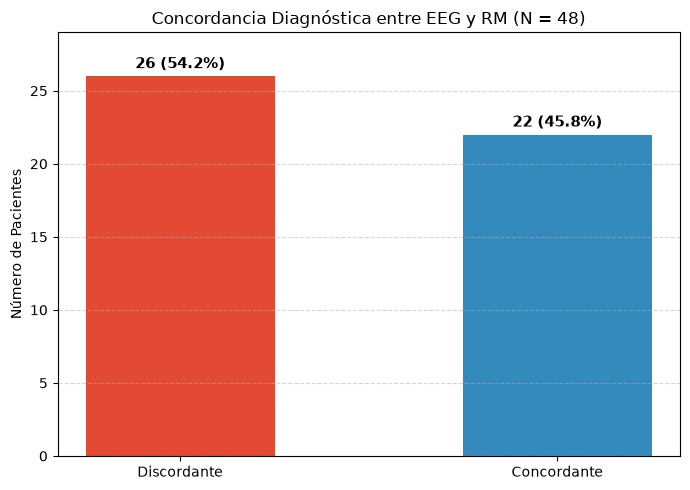

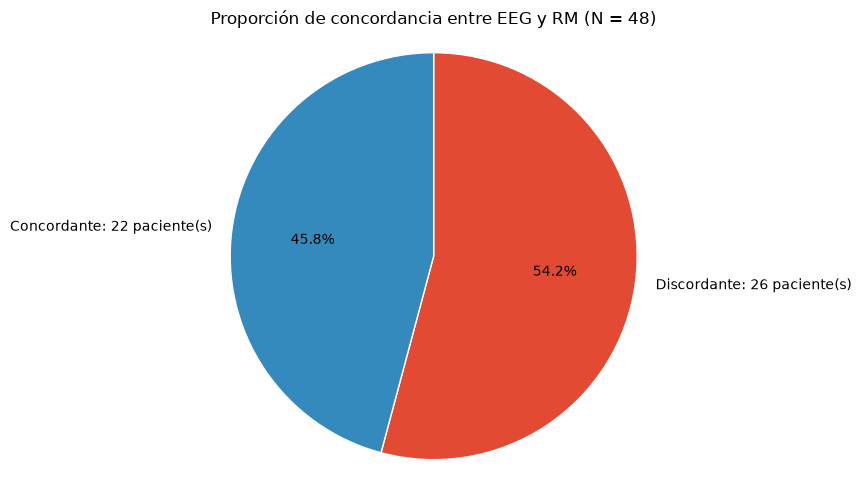

Conteo detallado de concordancia:
Concordancia
Discordante    26
Concordante    22


In [8]:
# Gráfico de Concordancia entre EEG y RM

import matplotlib.pyplot as plt

mask_valid = ~(
    df['Resultado EEG'].fillna('').astype(str).str.contains('Sin informe', case=False, na=False)
    | df['Resultado RM'].fillna('').astype(str).str.contains('Sin informe', case=False, na=False)
)
df_valid = df.loc[mask_valid].copy()

def estado_examen(valor):
    valor = str(valor).lower()
    if any(k in valor for k in ['alterado', 'no clasificable', 'anormal', 'patologico', 'patológico']):
        return 'Alterado'
    elif 'normal' in valor:
        return 'Normal'
    return 'No clasificado'

df_valid['Estado_EEG'] = df_valid['Resultado EEG'].apply(estado_examen)
df_valid['Estado_RM'] = df_valid['Resultado RM'].apply(estado_examen)

df_valid['Concordancia'] = df_valid.apply(
    lambda r: 'Concordante' if r['Estado_EEG'] == r['Estado_RM'] else 'Discordante',
    axis=1
)

concordancia_counts = df_valid['Concordancia'].value_counts()
concordancia_pct = (concordancia_counts / len(df_valid) * 100).round(1)

labels = concordancia_counts.index
values = concordancia_counts.values
pcts = concordancia_pct.values

plt.figure(figsize=(7, 5))
colors = ['#E24A33', '#348ABD']  # Discordante (rojo), Concordante (azul)
bars = plt.bar(labels, values, color=colors, width=0.5)

plt.title(f'Concordancia Diagnóstica entre EEG y RM (N = {len(df_valid)})')
plt.ylabel('Número de Pacientes')
plt.ylim(0, max(values) + 3)
plt.grid(axis='y', linestyle='--', alpha=0.5)

for bar, val, pct in zip(bars, values, pcts):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        val + 0.3,
        f'{val} ({pct}%)',
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.pie(
    concordancia_counts.values,
    labels=[f'{label}: {count} paciente(s)' for label, count in concordancia_counts.items()],
    colors=[{'Discordante': '#E24A33', 'Concordante': '#348ABD'}[label] for label in concordancia_counts.index],
    autopct='%1.1f%%',
    startangle=90,
    counterclock=False,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1},
    textprops={'fontsize': 10}
)
plt.title(f'Proporción de concordancia entre EEG y RM (N = {len(df_valid)})')
plt.axis('equal')
plt.tight_layout()
plt.show()

print("Conteo detallado de concordancia:")
print(concordancia_counts.to_string())


La clasificación normal/alterado se comparó por paciente en una tabla 2×2. El acuerdo observado fue 22/48 (45,8%) y hubo 26/48 (54,2%) discordancias. También se informa Kappa de Cohen con intervalo bootstrap del 95%. El acuerdo diagnóstico global no equivale a concordancia topográfica ni mide exactitud diagnóstica.

### Resultados descriptivos de EEG y RM según sexo

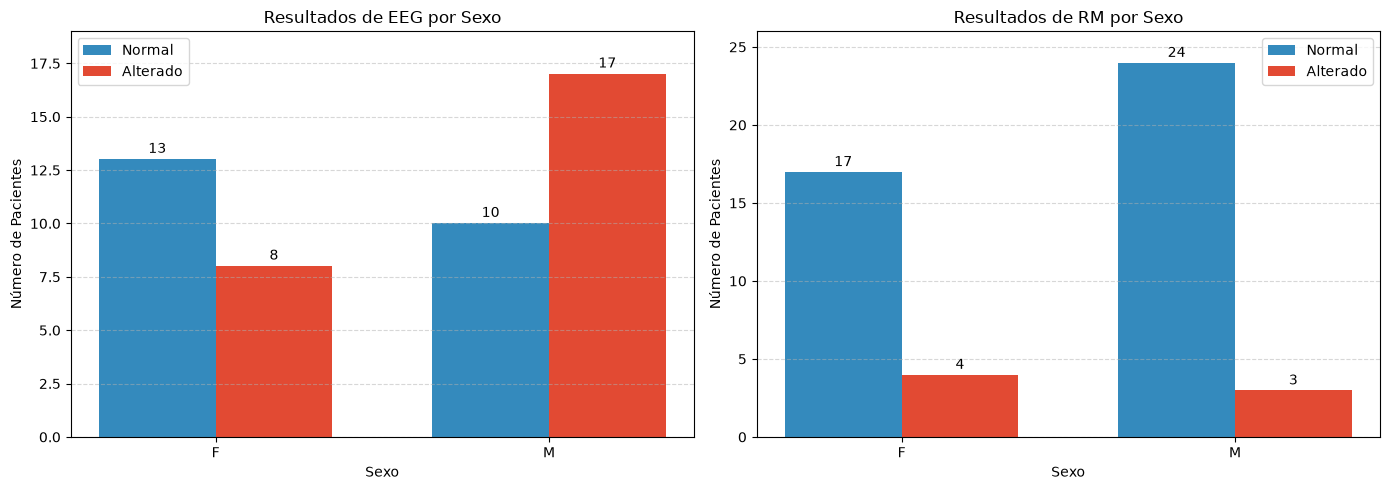

Frecuencia por Sexo - EEG:
Estado_EEG  Alterado  Normal
Sexo                        
F                  8      13
M                 17      10

Frecuencia por Sexo - RM:
Estado_RM  Alterado  Normal
Sexo                       
F                 4      17
M                 3      24


In [9]:
# Gráfico de resultados de EEG y RM por Sexo (Normal vs Alterado)

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

mask_valid = ~(
    df['Resultado EEG'].fillna('').astype(str).str.contains('Sin informe', case=False, na=False)
    | df['Resultado RM'].fillna('').astype(str).str.contains('Sin informe', case=False, na=False)
)
df_valid = df.loc[mask_valid].copy()

def estado_examen(valor):
    valor = str(valor).lower()
    if any(k in valor for k in ['alterado', 'no clasificable', 'anormal', 'patologico', 'patológico']):
        return 'Alterado'
    elif 'normal' in valor:
        return 'Normal'
    return 'No clasificado'

df_valid['Estado_EEG'] = df_valid['Resultado EEG'].apply(estado_examen)
df_valid['Estado_RM'] = df_valid['Resultado RM'].apply(estado_examen)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, (examen, col_estado) in enumerate([('EEG', 'Estado_EEG'), ('RM', 'Estado_RM')]):
    pivot = pd.crosstab(df_valid['Sexo'], df_valid[col_estado])
    
    # Asegurar orden Normal y Alterado
    for col in ['Normal', 'Alterado']:
        if col not in pivot.columns:
            pivot[col] = 0
    pivot = pivot[['Normal', 'Alterado']]
    
    ax = axes[i]
    x = np.arange(len(pivot.index))
    width = 0.35
    
    rects1 = ax.bar(x - width/2, pivot['Normal'], width, label='Normal', color='#348ABD')
    rects2 = ax.bar(x + width/2, pivot['Alterado'], width, label='Alterado', color='#E24A33')
    
    ax.set_title(f'Resultados de {examen} por Sexo')
    ax.set_xlabel('Sexo')
    ax.set_ylabel('Número de Pacientes')
    ax.set_xticks(x)
    ax.set_xticklabels(pivot.index)
    ax.set_ylim(0, max(pivot.max()) + 2)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.legend()
    
    # Etiquetas sobre las barras
    for rects in [rects1, rects2]:
        for bar in rects:
            height = bar.get_height()
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                height + 0.15,
                f'{int(height)}',
                ha='center',
                va='bottom',
                fontsize=10
            )

plt.tight_layout()
plt.show()

print("Frecuencia por Sexo - EEG:")
print(pd.crosstab(df_valid['Sexo'], df_valid['Estado_EEG']))
print("\nFrecuencia por Sexo - RM:")
print(pd.crosstab(df_valid['Sexo'], df_valid['Estado_RM']))


**Interpretación descriptiva:**
* **EEG:** En mujeres, 8/21 resultados fueron alterados (38,1%); en hombres, 17/27 (63,0%).
* **RM:** En mujeres, 4/21 fueron alteradas (19,0%); en hombres, 3/27 (11,1%).
* Las diferencias describen esta cohorte; no demuestran asociación ni causalidad. Hubo 7 RM alteradas y falta la edad de un participante.

La edad y el sexo se presentan como características de la cohorte y análisis secundarios, no como evidencia de factores asociados.

In [10]:
import pandas as pd
from IPython.display import display, Markdown

eeg_localizaciones = (
    df_valid.loc[(df_valid['Estado_EEG'] == 'Alterado') & ~df_valid['Localización EEG'].fillna('').str.contains('pendiente', case=False), 'Localización EEG']
    .dropna()
    .value_counts()
    .rename_axis('Localización EEG')
    .reset_index(name='Número de exámenes')
)
rm_localizaciones = (
    df_valid.loc[(df_valid['Estado_RM'] == 'Alterado') & ~df_valid['Localización RM'].fillna('').str.contains('pendiente', case=False), 'Localización RM']
    .dropna()
    .value_counts()
    .rename_axis('Localización RM')
    .reset_index(name='Número de exámenes')
)

display(Markdown(f"### EEG — Distribución de localizaciones en casos alterados (N = {(df_valid['Estado_EEG'] == 'Alterado').sum()})"))
display(eeg_localizaciones)
display(Markdown(f"### RM — Distribución de localizaciones en casos alterados (N = {(df_valid['Estado_RM'] == 'Alterado').sum()})"))
display(rm_localizaciones)
print(f"EEG alterados pendientes de codificación: {df_valid.loc[df_valid['Estado_EEG'] == 'Alterado', 'Localización EEG'].fillna('').str.contains('pendiente', case=False).sum()}")
print(f"RM alteradas pendientes de codificación: {df_valid.loc[df_valid['Estado_RM'] == 'Alterado', 'Localización RM'].fillna('').str.contains('pendiente', case=False).sum()}")
display(Markdown("*Las categorías mixtas se mantienen como fueron informadas; no se desglosan por lóbulo.*"))

### EEG — Distribución de localizaciones en casos alterados (N = 25)

,Localización EEG,Número de exámenes
0,Fronto-central,2
1,Fronto-temporal,2
2,Occipital,2
3,Generalizada,2
4,Parietal / temporo-parietal,1
5,Centro-parietal,1
6,Posterior,1
7,Temporal anterior / fronto-centro-temporal,1
8,Temporal anterior y media,1
9,"Multifocal: centro-parietal, frontal y temporal",1


### RM — Distribución de localizaciones en casos alterados (N = 7)

,Localización RM,Número de exámenes
0,Ventricular / occipital,1
1,Frontal,1
2,Periventricular occipital,1


EEG alterados pendientes de codificación: 6
RM alteradas pendientes de codificación: 4


*Las categorías mixtas se mantienen como fueron informadas; no se desglosan por lóbulo.*

## Análisis principal y conclusión para la cohorte de 48 pacientes

La tabla de concordancia se calcula directamente desde `Resultado EEG` y `Resultado RM`, no desde la columna preexistente `Concordancia global`. Se informa acuerdo observado, Kappa de Cohen con intervalo bootstrap pareado del 95%, y McNemar exacto como análisis secundario de la diferencia entre discordancias direccionales. Edad y sexo se describen por separado; la localización topográfica se considera exploratoria y no se estima Kappa topográfico si no hay suficientes pares completos.

In [11]:
import math
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

analisis = df_valid.copy()
if len(analisis) != 48:
    raise ValueError(f"Se esperaban 48 pacientes evaluables; se encontraron {len(analisis)}.")

analisis['Estado EEG'] = analisis['Resultado EEG'].astype(str).str.strip().str.lower().map({'alterado': 'Alterado', 'normal': 'Normal'})
analisis['Estado RM'] = analisis['Resultado RM'].astype(str).str.strip().str.lower().map({'alterado': 'Alterado', 'normal': 'Normal'})
if analisis[['Estado EEG', 'Estado RM']].isna().any().any():
    raise ValueError('Hay resultados EEG/RM sin una clasificación normal/alterado reconocida.')

n = len(analisis)
eeg_alterado = analisis['Estado EEG'].eq('Alterado').to_numpy()
rm_alterado = analisis['Estado RM'].eq('Alterado').to_numpy()
tabla_conteos = pd.crosstab(analisis['Estado EEG'], analisis['Estado RM']).reindex(
    index=['Alterado', 'Normal'], columns=['Alterado', 'Normal'], fill_value=0
)
tabla_conteos.index.name = 'Resultado EEG'
tabla_conteos.columns.name = 'Resultado RM'
tabla_conteos_con_total = tabla_conteos.copy()
tabla_conteos_con_total.loc['Total'] = tabla_conteos_con_total.sum(axis=0)
tabla_conteos_con_total['Total'] = tabla_conteos_con_total.sum(axis=1)
display(Markdown('### Tabla 2×2 de resultados (frecuencias absolutas)'))
display(tabla_conteos_con_total)
display(Markdown('### Tabla 2×2 (% del total de la cohorte)'))
display((tabla_conteos_con_total / n * 100).round(1))

concordantes = int((eeg_alterado == rm_alterado).sum())
discordantes_eeg_alterado = int((eeg_alterado & ~rm_alterado).sum())
discordantes_rm_alterada = int((~eeg_alterado & rm_alterado).sum())
acuerdo_observado = concordantes / n
p_eeg_alterado = eeg_alterado.mean()
p_rm_alterada = rm_alterado.mean()
acuerdo_esperado = p_eeg_alterado * p_rm_alterada + (1 - p_eeg_alterado) * (1 - p_rm_alterada)
kappa_cohen = (acuerdo_observado - acuerdo_esperado) / (1 - acuerdo_esperado)

rng = np.random.default_rng(20261030)
n_bootstrap = 20_000
indices_bootstrap = rng.integers(0, n, size=(n_bootstrap, n))
eeg_bootstrap = eeg_alterado[indices_bootstrap]
rm_bootstrap = rm_alterado[indices_bootstrap]
acuerdo_bootstrap = (eeg_bootstrap == rm_bootstrap).mean(axis=1)
p_eeg_bootstrap = eeg_bootstrap.mean(axis=1)
p_rm_bootstrap = rm_bootstrap.mean(axis=1)
esperado_bootstrap = p_eeg_bootstrap * p_rm_bootstrap + (1 - p_eeg_bootstrap) * (1 - p_rm_bootstrap)
kappa_bootstrap = np.divide(
    acuerdo_bootstrap - esperado_bootstrap,
    1 - esperado_bootstrap,
    out=np.full(n_bootstrap, np.nan),
    where=(1 - esperado_bootstrap) > 0,
)
kappa_bootstrap = kappa_bootstrap[np.isfinite(kappa_bootstrap)]
ic_kappa = np.quantile(kappa_bootstrap, [0.025, 0.975])
tabla_acuerdo = pd.DataFrame([
    ('Acuerdo observado', f'{concordantes}/{n} ({100 * acuerdo_observado:.1f}%)'),
    ('Acuerdo esperado por azar', f'{100 * acuerdo_esperado:.1f}%'),
    ('Kappa de Cohen', f'{kappa_cohen:.3f}'),
    ('IC bootstrap 95% de Kappa', f'[{ic_kappa[0]:.3f}, {ic_kappa[1]:.3f}]'),
], columns=['Medida', 'Resultado'])
display(Markdown('### Acuerdo observado y Kappa de Cohen'))
display(tabla_acuerdo)
print(f'Kappa de Cohen = {kappa_cohen:.3f}; IC bootstrap percentil 95% = [{ic_kappa[0]:.3f}, {ic_kappa[1]:.3f}] ({len(kappa_bootstrap):,} réplicas válidas de {n_bootstrap:,}).')
print(f'El IC se obtuvo por remuestreo pareado de pacientes, con semilla fija; es una aproximación y debe interpretarse con cautela por el tamaño y el desbalance de categorías.')
print(f'Discordancia direccional: EEG alterado/RM normal = {discordantes_eeg_alterado}; EEG normal/RM alterada = {discordantes_rm_alterada}.')

n_discordantes = discordantes_eeg_alterado + discordantes_rm_alterada
cola_binomial = sum(math.comb(n_discordantes, k) for k in range(min(discordantes_eeg_alterado, discordantes_rm_alterada) + 1)) / (2 ** n_discordantes)
p_mcnemar_exacto = min(1.0, 2 * cola_binomial) if n_discordantes else 1.0
print(f'McNemar exacto bilateral (secundario, compara discordancias marginales): p = {p_mcnemar_exacto:.4f}. No mide concordancia ni identifica cuál examen es más exacto.')

display(Markdown('### Edad: descripción global y según resultado de cada examen'))
analisis['Edad (años)'] = pd.to_numeric(analisis['Edad (años)'], errors='coerce')
resumen_edad_global = analisis['Edad (años)'].describe().to_frame('Edad (años)').round(2)
display(resumen_edad_global)
for examen, estado in [('EEG', 'Estado EEG'), ('RM', 'Estado RM')]:
    resumen_edad = analisis.groupby(estado, observed=True)['Edad (años)'].agg(
        N='count', Media='mean', Desviación_estándar='std', Mediana='median',
        Q1=lambda valores: valores.quantile(0.25),
        Q3=lambda valores: valores.quantile(0.75),
    ).round(2)
    print(f'Edad según resultado de {examen} (el N corresponde a edades disponibles):')
    display(resumen_edad)

analisis['Rango de edad'] = pd.cut(
    analisis['Edad (años)'], bins=[0, 3, 6, 9, 15], right=False,
    labels=['0–2', '3–5', '6–8', '9–14'], include_lowest=True,
).astype('object').fillna('Sin dato')
for examen, estado in [('EEG', 'Estado EEG'), ('RM', 'Estado RM')]:
    print(f'{examen}: resultado por rango de edad (frecuencias; Sin dato se conserva):')
    display(pd.crosstab(analisis['Rango de edad'], analisis[estado]).reindex(
        index=['0–2', '3–5', '6–8', '9–14', 'Sin dato'],
        columns=['Alterado', 'Normal'], fill_value=0,
    ))

display(Markdown('### Resultados por sexo (n y porcentaje dentro de cada sexo)'))
for examen, estado in [('EEG', 'Estado EEG'), ('RM', 'Estado RM')]:
    conteos_sexo = pd.crosstab(analisis['Sexo'], analisis[estado]).reindex(columns=['Alterado', 'Normal'], fill_value=0)
    porcentajes_sexo = (conteos_sexo.div(conteos_sexo.sum(axis=1), axis=0) * 100).round(1)
    print(examen)
    display(pd.concat({'n': conteos_sexo, '% dentro de sexo': porcentajes_sexo}, axis=1))

display(Markdown('### Evaluabilidad de la concordancia topográfica'))
patron_pendiente = 'pendiente|por codificar|sin consignar|no consignad'
alterados_eeg = analisis.loc[analisis['Estado EEG'] == 'Alterado']
alterados_rm = analisis.loc[analisis['Estado RM'] == 'Alterado']
pendientes_eeg = int(alterados_eeg['Localización EEG'].fillna('').str.contains(patron_pendiente, case=False, regex=True).sum())
pendientes_rm = int(alterados_rm['Localización RM'].fillna('').str.contains(patron_pendiente, case=False, regex=True).sum())
ambos_alterados = analisis.loc[(analisis['Estado EEG'] == 'Alterado') & (analisis['Estado RM'] == 'Alterado')].copy()
topografia_pendiente = pd.Series(False, index=ambos_alterados.index)
for columna in ['Localización EEG', 'Lateralidad EEG', 'Localización RM', 'Lateralidad RM']:
    topografia_pendiente |= ambos_alterados[columna].fillna('').str.contains(patron_pendiente, case=False, regex=True)
pares_topograficos_evaluables = int((~topografia_pendiente).sum())
print(f'EEG alterados con localización pendiente: {pendientes_eeg}/{len(alterados_eeg)}.')
print(f'RM alteradas con localización pendiente: {pendientes_rm}/{len(alterados_rm)}.')
print(f'Pacientes con ambos exámenes alterados: {len(ambos_alterados)}; pares con localización y lateralidad disponibles en ambos: {pares_topograficos_evaluables}.')
if pares_topograficos_evaluables < 2:
    print('No se estima Kappa topográfico: la cantidad de pares completos es insuficiente para una comparación interpretable.')

display(Markdown('### Auditoría de la variable de concordancia preexistente'))
concordancia_derivada = eeg_alterado == rm_alterado
etiqueta_base = analisis['Concordancia global'].fillna('').astype(str).str.strip().str.lower()
etiqueta_concordante = etiqueta_base.str.startswith('concordante')
etiqueta_discordante = etiqueta_base.str.startswith('discordante')
etiquetas_coherentes = (concordancia_derivada & etiqueta_concordante) | (~concordancia_derivada & etiqueta_discordante)
print(f"Registros cuya etiqueta preexistente coincide con la clasificación derivada de EEG/RM: {int(etiquetas_coherentes.sum())}/{n}.")
print('El análisis principal usa los resultados de EEG y RM; la variable preexistente contiene etiquetas con distinto nivel de detalle.')

n_edad = int(analisis['Edad (años)'].notna().sum())
media_edad = analisis['Edad (años)'].mean()
desv_edad = analisis['Edad (años)'].std()
if ic_kappa[0] <= 0 <= ic_kappa[1]:
    interpretacion_kappa = 'El intervalo bootstrap incluye 0; con esta estimación no se demuestra un acuerdo distinto del esperado por azar con precisión.'
else:
    interpretacion_kappa = 'El intervalo bootstrap no incluye 0; interpretar esta estimación con cautela por el tamaño de la cohorte y el desbalance de categorías.'
conclusion = (
    f'### Conclusión del análisis\n\n'
    f'Se analizaron {n} pacientes con resultados disponibles de ambos exámenes; la edad estuvo disponible en {n_edad}. '
    f'El EEG fue alterado en {int(eeg_alterado.sum())}/{n} ({100 * eeg_alterado.mean():.1f}%) y la RM en {int(rm_alterado.sum())}/{n} ({100 * rm_alterado.mean():.1f}%). '
    f'La clasificación coincidió en {concordantes}/{n} ({100 * acuerdo_observado:.1f}%) y discrepó en {n_discordantes}/{n} ({100 * n_discordantes / n:.1f}%); '
    f'{discordantes_eeg_alterado} casos fueron EEG alterado/RM normal y {discordantes_rm_alterada} EEG normal/RM alterada. '
    f'Kappa fue {kappa_cohen:.3f} (IC bootstrap 95% {ic_kappa[0]:.3f} a {ic_kappa[1]:.3f}). {interpretacion_kappa} '
    f'La prueba exacta de McNemar (p={p_mcnemar_exacto:.4f}) señala una diferencia en las discordancias marginales, pero no mide acuerdo ni permite concluir superioridad diagnóstica. '
    f'La edad media fue {media_edad:.2f} años (DE {desv_edad:.2f}); estos análisis por edad y sexo son descriptivos. '
    f'La evaluación topográfica no es concluyente: solo {pares_topograficos_evaluables} de {len(ambos_alterados)} pares con ambos exámenes alterados tienen localización y lateralidad completas. '
    'En conjunto, estos datos describen el acuerdo diagnóstico global de la cohorte, pero no establecen sensibilidad, causalidad ni concordancia anatómica robusta.'
)
display(Markdown(conclusion))

### Tabla 2×2 de resultados (frecuencias absolutas)

Resultado RM,Alterado,Normal,Total
Resultado EEG,,,
Alterado,3,22,25
Normal,4,19,23
Total,7,41,48


### Tabla 2×2 (% del total de la cohorte)

Resultado RM,Alterado,Normal,Total
Resultado EEG,,,
Alterado,6.2,45.8,52.1
Normal,8.3,39.6,47.9
Total,14.6,85.4,100.0


### Acuerdo observado y Kappa de Cohen

,Medida,Resultado
0,Acuerdo observado,22/48 (45.8%)
1,Acuerdo esperado por azar,48.5%
2,Kappa de Cohen,-0.052
3,IC bootstrap 95% de Kappa,"[-0.250, 0.141]"


... (17 outputs left out)

EEG alterados con localización pendiente: 6/25.
RM alteradas con localización pendiente: 4/7.
Pacientes con ambos exámenes alterados: 3; pares con localización y lateralidad disponibles en ambos: 1.
No se estima Kappa topográfico: la cantidad de pares completos es insuficiente para una comparación interpretable.


### Auditoría de la variable de concordancia preexistente

Registros cuya etiqueta preexistente coincide con la clasificación derivada de EEG/RM: 48/48.
El análisis principal usa los resultados de EEG y RM; la variable preexistente contiene etiquetas con distinto nivel de detalle.


### Conclusión del análisis

Se analizaron 48 pacientes con resultados disponibles de ambos exámenes; la edad estuvo disponible en 47. El EEG fue alterado en 25/48 (52.1%) y la RM en 7/48 (14.6%). La clasificación coincidió en 22/48 (45.8%) y discrepó en 26/48 (54.2%); 22 casos fueron EEG alterado/RM normal y 4 EEG normal/RM alterada. Kappa fue -0.052 (IC bootstrap 95% -0.250 a 0.141). El intervalo bootstrap incluye 0; con esta estimación no se demuestra un acuerdo distinto del esperado por azar con precisión. La prueba exacta de McNemar (p=0.0005) señala una diferencia en las discordancias marginales, pero no mide acuerdo ni permite concluir superioridad diagnóstica. La edad media fue 6.52 años (DE 3.13); estos análisis por edad y sexo son descriptivos. La evaluación topográfica no es concluyente: solo 1 de 3 pares con ambos exámenes alterados tienen localización y lateralidad completas. En conjunto, estos datos describen el acuerdo diagnóstico global de la cohorte, pero no establecen sensibilidad, causalidad ni concordancia anatómica robusta.

### Resumen descriptivo de los cuatro patrones diagnósticos

Cada paciente se cuenta una sola vez y se clasifica según los resultados de ambos exámenes. Esta agrupación descriptiva facilita la lectura de la tabla de concordancia; no es un algoritmo de clustering.

,Pacientes (n),Porcentaje (%)
Patrón diagnóstico,,
Ambos normales,19,39.6
Solo EEG alterado,22,45.8
Solo RM alterada,4,8.3
Ambos alterados,3,6.2


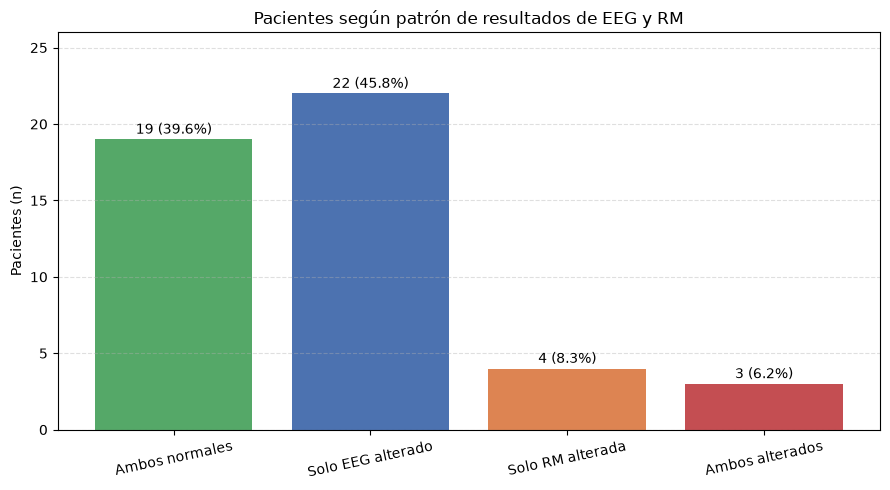

La categoría con más pacientes fue 'Solo EEG alterado' (22/48). Los porcentajes usan como denominador los 48 pacientes.


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

patrones_orden = ['Ambos normales', 'Solo EEG alterado', 'Solo RM alterada', 'Ambos alterados']
analisis['Patrón diagnóstico'] = np.select(
    [
        analisis['Estado EEG'].eq('Normal') & analisis['Estado RM'].eq('Normal'),
        analisis['Estado EEG'].eq('Alterado') & analisis['Estado RM'].eq('Normal'),
        analisis['Estado EEG'].eq('Normal') & analisis['Estado RM'].eq('Alterado'),
        analisis['Estado EEG'].eq('Alterado') & analisis['Estado RM'].eq('Alterado'),
    ],
    patrones_orden,
    default='Revisar clasificación',
)
conteo_patrones = analisis['Patrón diagnóstico'].value_counts().reindex(patrones_orden, fill_value=0)
tabla_patrones = pd.DataFrame({
    'Pacientes (n)': conteo_patrones,
    'Porcentaje (%)': (conteo_patrones / len(analisis) * 100).round(1),
})
display(tabla_patrones)

fig, ax = plt.subplots(figsize=(9, 5))
colores = ['#55A868', '#4C72B0', '#DD8452', '#C44E52']
barras = ax.bar(tabla_patrones.index, tabla_patrones['Pacientes (n)'], color=colores)
ax.set_title('Pacientes según patrón de resultados de EEG y RM')
ax.set_ylabel('Pacientes (n)')
ax.set_ylim(0, int(tabla_patrones['Pacientes (n)'].max()) + 4)
ax.tick_params(axis='x', rotation=12)
ax.grid(axis='y', linestyle='--', alpha=0.4)
for barra, cantidad, porcentaje in zip(barras, tabla_patrones['Pacientes (n)'], tabla_patrones['Porcentaje (%)']):
    ax.text(barra.get_x() + barra.get_width() / 2, cantidad + 0.15, f'{cantidad} ({porcentaje:.1f}%)', ha='center', va='bottom')
plt.tight_layout()
plt.show()

print(f"La categoría con más pacientes fue '{tabla_patrones['Pacientes (n)'].idxmax()}' ({int(tabla_patrones['Pacientes (n)'].max())}/{len(analisis)}). Los porcentajes usan como denominador los 48 pacientes.")
